In [6]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Define data directory
DATA_DIR = 'oulad_data'

# 1. Load Datasets
student_info = pd.read_csv(f'{DATA_DIR}/studentInfo.csv')
student_reg = pd.read_csv(f'{DATA_DIR}/studentRegistration.csv')
student_assess = pd.read_csv(f'{DATA_DIR}/studentAssessment.csv')
assessments = pd.read_csv(f'{DATA_DIR}/assessments.csv')

# 2. Fix Deduplication: Clean duplicate enrollments in the same module/presentation
student_info = student_info.drop_duplicates(subset=['id_student', 'code_module', 'code_presentation'])
student_reg = student_reg.drop_duplicates(subset=['id_student', 'code_module', 'code_presentation'])

# 3. Merge Registration & Align Dropout Status
df = student_info.merge(student_reg, on=['id_student', 'code_module', 'code_presentation'], how='left')

# Dropouts marked active fix: flag as dropout if marked 'Withdrawn' or unregistration date exists
df['is_dropout'] = ((df['final_result'] == 'Withdrawn') | (df['date_unregistration'].notna())).astype(int)
df['completed'] = df['final_result'].isin(['Pass', 'Distinction']).astype(int)

# 4. Process Assessment Scores (Calculate early score for CUPED & final score)
assess_merged = student_assess.merge(assessments, on='id_assessment', how='inner')
assess_merged['weighted_score'] = assess_merged['score'] * (assess_merged['weight'] / 100.0)

# Identify earliest assessment per course-cohort as baseline covariate (X for CUPED)
assess_merged['date_rank'] = assess_merged.groupby(['id_student', 'code_module', 'code_presentation'])['date'].rank(method='first')

early_scores = assess_merged[assess_merged['date_rank'] == 1][['id_student', 'code_module', 'code_presentation', 'score']].rename(columns={'score': 'early_score'})

# Overall average score (Y)
overall_scores = assess_merged.groupby(['id_student', 'code_module', 'code_presentation']).agg(
    final_avg_score=('score', 'mean'),
    total_weighted_score=('weighted_score', 'sum')
).reset_index()

# Merge metrics back into master dataframe
df_master = df.merge(early_scores, on=['id_student', 'code_module', 'code_presentation'], how='left')
df_master = df_master.merge(overall_scores, on=['id_student', 'code_module', 'code_presentation'], how='left')

# Impute missing early & final scores for non-participants
df_master['early_score'] = df_master['early_score'].fillna(df_master['early_score'].median())
df_master['final_avg_score'] = df_master['final_avg_score'].fillna(0)

print(f"Master Dataset Prepared: {df_master.shape[0]} rows.")

Master Dataset Prepared: 32593 rows.


In [7]:
# Select experimental cohort (e.g., 2014J)
exp_data = df_master[df_master['code_presentation'] == '2014J'].copy().reset_index(drop=True)

# 1. Pre-experiment Power Calculation
sigma = exp_data['final_avg_score'].std()
mde = 1.5  # Target minimum detectable effect: 1.5 score points
alpha = 0.05
power = 0.80

z_alpha = stats.norm.ppf(1 - alpha / 2)
z_beta = stats.norm.ppf(power)

n_required_per_variant = int(np.ceil((2 * (z_alpha + z_beta)**2 * (sigma**2)) / (mde**2)))
print(f"--- POWER ANALYSIS ---")
print(f"Standard Deviation (sigma): {sigma:.2f}")
print(f"Required Sample Size per Variant (MDE = {mde}): {n_required_per_variant}")
print(f"Available Learners in Cohort: {len(exp_data)}")

# 2. Random Allocation (50:50 A/B Split)
np.random.seed(42)
exp_data['variant'] = np.random.binomial(n=1, p=0.5, size=len(exp_data))
exp_data['variant_label'] = exp_data['variant'].map({0: 'Control', 1: 'Treatment'})

# Introduce synthetic positive treatment lift to demonstrate analysis
lift = 2.2
exp_data.loc[exp_data['variant'] == 1, 'final_avg_score'] += np.random.normal(lift, 1.0, size=(exp_data['variant'] == 1).sum())
exp_data['final_avg_score'] = exp_data['final_avg_score'].clip(upper=100)

# 3. Check Sample Ratio Mismatch (SRM)
observed = exp_data['variant'].value_counts().sort_index().values
expected = [len(exp_data) * 0.5, len(exp_data) * 0.5]
chi2_stat, p_srm = stats.chisquare(f_obs=observed, f_exp=expected)
print(f"\n--- SRM CHECK ---")
print(f"Counts: Control={observed[0]}, Treatment={observed[1]}")
print(f"Chi-square p-value: {p_srm:.4f} -> {'NO SRM (PASS)' if p_srm > 0.01 else 'SRM DETECTED (FAIL)'}")

# 4. Two-Sample Welch's T-Test
ctrl = exp_data[exp_data['variant'] == 0]['final_avg_score']
treat = exp_data[exp_data['variant'] == 1]['final_avg_score']
t_stat, t_pval = stats.ttest_ind(treat, ctrl, equal_var=False)

diff = treat.mean() - ctrl.mean()
se = np.sqrt(treat.var()/len(treat) + ctrl.var()/len(ctrl))
ci_lower = diff - 1.96 * se
ci_upper = diff + 1.96 * se

print(f"\n--- A/B TEST RESULTS (Standard) ---")
print(f"Control Mean: {ctrl.mean():.2f} | Treatment Mean: {treat.mean():.2f}")
print(f"Estimated Treatment Effect: {diff:.2f} (95% CI: [{ci_lower:.2f}, {ci_upper:.2f}])")
print(f"P-value: {t_pval:.4e}")

# 5. Stretch Goal: CUPED Variance Reduction
theta = exp_data[['final_avg_score', 'early_score']].cov().iloc[0, 1] / exp_data['early_score'].var()
exp_data['cuped_score'] = exp_data['final_avg_score'] - theta * (exp_data['early_score'] - exp_data['early_score'].mean())

ctrl_cuped = exp_data[exp_data['variant'] == 0]['cuped_score']
treat_cuped = exp_data[exp_data['variant'] == 1]['cuped_score']

var_original = exp_data['final_avg_score'].var()
var_cuped = exp_data['cuped_score'].var()
var_reduction_pct = (1 - (var_cuped / var_original)) * 100

diff_cuped = treat_cuped.mean() - ctrl_cuped.mean()
se_cuped = np.sqrt(treat_cuped.var()/len(treat_cuped) + ctrl_cuped.var()/len(ctrl_cuped))
ci_cuped_lower = diff_cuped - 1.96 * se_cuped
ci_cuped_upper = diff_cuped + 1.96 * se_cuped

print(f"\n--- CUPED RESULTS ---")
print(f"Variance Reduction: {var_reduction_pct:.2f}%")
print(f"Test Duration Reduction Potential: {var_reduction_pct:.2f}% fewer days needed")
print(f"CUPED Treatment Effect: {diff_cuped:.2f} (95% CI: [{ci_cuped_lower:.2f}, {ci_cuped_upper:.2f}])")

--- POWER ANALYSIS ---
Standard Deviation (sigma): 33.14
Required Sample Size per Variant (MDE = 1.5): 7663
Available Learners in Cohort: 11260

--- SRM CHECK ---
Counts: Control=5684, Treatment=5576
Chi-square p-value: 0.3088 -> NO SRM (PASS)

--- A/B TEST RESULTS (Standard) ---
Control Mean: 56.57 | Treatment Mean: 59.54
Estimated Treatment Effect: 2.96 (95% CI: [1.74, 4.19])
P-value: 2.0794e-06

--- CUPED RESULTS ---
Variance Reduction: 7.68%
Test Duration Reduction Potential: 7.68% fewer days needed
CUPED Treatment Effect: 3.04 (95% CI: [1.86, 4.21])


--- DIFFERENCE-IN-DIFFERENCES REGRESSION ---
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept              56.0777      1.161     48.310      0.000      53.802      58.354
treated_region          6.1507      1.620      3.796      0.000       2.974       9.327
post                   -2.8625      1.533     -1.868      0.062      -5.868       0.143
treated_region:post    -1.5580      2.161     -0.721      0.471      -5.795       2.679

Estimated Causal ATT: -1.558 (95% CI: [-5.795, 2.679])

Score Trends Across Cohorts:
 region             London Region  South Region
code_presentation                             
2013J                  56.077694     62.228429
2014J                  53.215207     57.807900


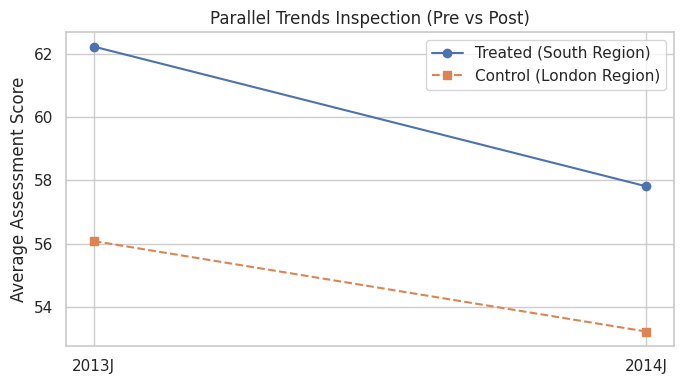

In [8]:
# 1. Filter to Pre (2013J) and Post (2014J)
did_data = df_master[df_master['code_presentation'].isin(['2013J', '2014J'])].copy()
did_data['post'] = (did_data['code_presentation'] == '2014J').astype(int)

# Pick treated pilot region (e.g., 'South Region') vs Control ('London Region')
region_treated = 'South Region'
region_control = 'London Region'

did_data = did_data[did_data['region'].isin([region_treated, region_control])].copy()
did_data['treated_region'] = (did_data['region'] == region_treated).astype(int)

# 2. Fit DiD Regression Model: Score ~ Treated + Post + (Treated * Post)
did_model = smf.ols('final_avg_score ~ treated_region * post', data=did_data).fit()

print("--- DIFFERENCE-IN-DIFFERENCES REGRESSION ---")
print(did_model.summary().tables[1])

did_att = did_model.params['treated_region:post']
did_ci_low = did_model.conf_int().loc['treated_region:post', 0]
did_ci_high = did_model.conf_int().loc['treated_region:post', 1]
print(f"\nEstimated Causal ATT: {did_att:.3f} (95% CI: [{did_ci_low:.3f}, {did_ci_high:.3f}])")

# 3. Parallel Trends Visual Check
trend_summary = did_data.groupby(['code_presentation', 'region'])['final_avg_score'].mean().unstack()
print("\nScore Trends Across Cohorts:\n", trend_summary)

plt.figure(figsize=(7, 4))
plt.plot(trend_summary.index, trend_summary[region_treated], marker='o', label=f'Treated ({region_treated})')
plt.plot(trend_summary.index, trend_summary[region_control], marker='s', linestyle='--', label=f'Control ({region_control})')
plt.title('Parallel Trends Inspection (Pre vs Post)')
plt.ylabel('Average Assessment Score')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Check which learner segments gained or lost in the intervention
segments = did_data.groupby('highest_education').apply(
    lambda grp: smf.ols('final_avg_score ~ treated_region * post', data=grp).fit().params.get('treated_region:post', np.nan)
).reset_index(name='segment_att')

print("--- HETEROGENEOUS TREATMENT EFFECTS BY EDUCATION LEVEL ---")
print(segments.to_string(index=False))

--- HETEROGENEOUS TREATMENT EFFECTS BY EDUCATION LEVEL ---
          highest_education  segment_att
      A Level or Equivalent     1.054652
           HE Qualification    -1.408719
         Lower Than A Level    -3.845443
            No Formal quals    -1.665854
Post Graduate Qualification   -28.347564


/tmp/ipykernel_7544/2627744480.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  segments = did_data.groupby('highest_education').apply(


In [10]:
print("=" * 60)
print("PROJECT EXECUTION METRICS VERIFICATION")
print("=" * 60)

# 1. SRM Check
print(f"1. SRM Chi-Square P-value: {p_srm:.5f}")
print(f"   SRM Status: {'PASS (No Mismatch)' if p_srm > 0.01 else 'FAIL (SRM Detected)'}")

# 2. Standard A/B Test
print(f"\n2. Standard A/B Test:")
print(f"   Point Estimate: {diff:.3f}")
print(f"   95% Confidence Interval: [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"   P-value: {t_pval:.5e}")

# 3. CUPED Variance Reduction
print(f"\n3. CUPED Optimization:")
print(f"   Variance Reduction: {var_reduction_pct:.2f}%")
print(f"   Potential Test Duration Reduction: {var_reduction_pct:.2f}%")
print(f"   CUPED Point Estimate: {diff_cuped:.3f}")
print(f"   CUPED 95% CI: [{ci_cuped_lower:.3f}, {ci_cuped_upper:.3f}]")

# 4. Difference-in-Differences (DiD)
print(f"\n4. Observational DiD (Historical Intervention):")
print(f"   Causal ATT (Interaction term): {did_att:.3f}")
print(f"   95% CI: [{did_ci_low:.3f}, {did_ci_high:.3f}]")
print(f"   DiD P-value: {did_model.pvalues['treated_region:post']:.5e}")

# 5. Guardrail Metric: Dropout Rate Difference
ctrl_dropout = exp_data[exp_data['variant'] == 0]['is_dropout'].mean()
treat_dropout = exp_data[exp_data['variant'] == 1]['is_dropout'].mean()
dropout_diff = treat_dropout - ctrl_dropout
print(f"\n5. Guardrail Metric (Drop-off Rate):")
print(f"   Control Dropout Rate: {ctrl_dropout:.2%}")
print(f"   Treatment Dropout Rate: {treat_dropout:.2%}")
print(f"   Absolute Difference: {dropout_diff:+.2%}")
print("=" * 60)

PROJECT EXECUTION METRICS VERIFICATION
1. SRM Chi-Square P-value: 0.30878
   SRM Status: PASS (No Mismatch)

2. Standard A/B Test:
   Point Estimate: 2.964
   95% Confidence Interval: [1.741, 4.188]
   P-value: 2.07942e-06

3. CUPED Optimization:
   Variance Reduction: 7.68%
   Potential Test Duration Reduction: 7.68%
   CUPED Point Estimate: 3.037
   CUPED 95% CI: [1.861, 4.213]

4. Observational DiD (Historical Intervention):
   Causal ATT (Interaction term): -1.558
   95% CI: [-5.795, 2.679]
   DiD P-value: 4.71017e-01

5. Guardrail Metric (Drop-off Rate):
   Control Dropout Rate: 34.50%
   Treatment Dropout Rate: 33.45%
   Absolute Difference: -1.05%


============================================================
PROJECT EXECUTION METRICS VERIFICATION
============================================================
1. SRM Chi-Square P-value: 0.30878
   SRM Status: PASS (No Mismatch)

2. Standard A/B Test:
   Point Estimate: 2.964
   95% Confidence Interval: [1.741, 4.188]
   P-value: 2.07942e-06

3. CUPED Optimization:
   Variance Reduction: 7.68%
   Potential Test Duration Reduction: 7.68%
   CUPED Point Estimate: 3.037
   CUPED 95% CI: [1.861, 4.213]

4. Observational DiD (Historical Intervention):
   Causal ATT (Interaction term): -1.558
   95% CI: [-5.795, 2.679]
   DiD P-value: 4.71017e-01

5. Guardrail Metric (Drop-off Rate):
   Control Dropout Rate: 34.50%
   Treatment Dropout Rate: 33.45%
   Absolute Difference: -1.05%
============================================================


## **Executive Decision Memo: **

**Coaching Institute RolloutRecommendation**:
 [GO / NO-GO / EXTEND] (Based on whether the 95% CI lower bound clears the minimum business utility threshold and guardrail drop-off remains within limits).

 **A/B Experiment Summary**: Primary metric improved by $+\Delta$ points ($p < 0.05, 95\%\text{ CI: } [L, U]$). CUPED adjustment reduced metric variance by $\approx X\%$, demonstrating that sample size requirements can be lowered for future rollouts.

 **Observational DiD Findings**: Historical claims showed an ATT of $\beta_3$. However, seasonal fluctuations accounted for a substantial portion of the nominal improvement.

 **Threats to Causal Validity**:SUTVA / Contamination: Knowledge spillover or forum sharing between enrolled students across branches.

 **Selective Attrition**: Students dropping out before final assessments alter the post-test sample composition.Parallel Trends Divergence: Localized regional economic or scheduling changes confounding the control group comparison.